#### 1. Depedencies and libraries

In [277]:
!pip install -q bertopic sentence-transformers transformers torch pandas numpy matplotlib seaborn scikit-learn scipy tqdm Sastrawi

preventing kernel crash

In [278]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

In [279]:
import torch
torch.set_num_threads(1)

In [280]:
import re
import textwrap
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

In [281]:
warnings.filterwarnings("ignore") # hides warning messages
sns.set_theme(style="whitegrid", context="notebook") # sets the theme for seaborn plots
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)


Declaring variables for config

In [282]:
csv_file = "psn_news_scraped.csv"
random_state = 42

embedding_model = "paraphrase-multilingual-MiniLM-L12-v2" # Indonesian + English
sentiment_model_id = "w11wo/indonesian-roberta-base-sentiment-classifier" # Indonesian text
sentiment_model_en = "cardiffnlp/twitter-roberta-base-sentiment" # English text

min_chars = 300 # dropping articles that's shorter than this number
min_sentences = 3 # checking if article mentions psn # of times
frequent_min_articles = 10 # minimum number for noise



#### 2. Data Loading

here loading data will be performed and to check the scrapped article or news data 

In [283]:
raw_data = pd.read_csv(csv_file)
print("Shape:", raw_data.shape)
raw_data.info()
raw_data.head(3)

Shape: (918, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   link          918 non-null    object
 1   title         918 non-null    object
 2   snippet       918 non-null    object
 3   date          918 non-null    object
 4   source        918 non-null    object
 5   article_url   824 non-null    object
 6   article_text  764 non-null    object
dtypes: object(7)
memory usage: 50.3+ KB


,link,title,snippet,date,source,article_url,article_text
0,https://news.google.com/rss/articles/CBMia0FVX3lxTE9DQkxuemUxa0otYVFQSTBzdFo1bDN3Z1owUzNCb0gzZlMtdHdyRDVyQmY0ZDZIaDl...,Berita Kini - Menkomdigi Meutya Hafid: Satelit Nusantara Lima Bukti Nyata Kedaulatan Digital Indonesia - Kementerian...,Berita Kini - Menkomdigi Meutya Hafid: Satelit Nusantara Lima Bukti Nyata Kedaulatan Digital Indonesia Kementerian K...,"Tue, 12 May 2026 07:00:00 GMT",Kementerian Komunikasi dan Digital,https://portal.komdigi.go.id/kanal-publik/berita-kini/10210,Menteri Komunikasi dan Digital Meutya Hafid menyatakan peluncuran dan pengoperasian Satelit Nusantara Lima merupakan...
1,https://news.google.com/rss/articles/CBMikwFBVV95cUxPX2tTSjhRSnRteVoybXJpejFROThRLURodlF4OVBieVlfVGpYUXAtbUhDYVJoNmJ...,KSP Dukung Pemerataan Internet di Daerah 3T Melalui Satelit N5 - Kantor Staf Presiden,KSP Dukung Pemerataan Internet di Daerah 3T Melalui Satelit N5 Kantor Staf Presiden,"Tue, 12 May 2026 07:00:00 GMT",Kantor Staf Presiden,https://www.ksp.go.id/ksp-dukung-pemerataan-internet-di-daerah-3t-melalui-satelit-n5.html,"Kepala Staf Kepresidenan, Jenderal TNI (Purn.) Prof. Dr. H. Dudung Abdurachman, S.E., M.M., M.H., menghadiri acara P..."
2,https://news.google.com/rss/articles/CBMiswFBVV95cUxObGktUThuSjBsV2wyVDRPam92aF9fOFo4MHNWeUotQ1Q5M1pQS0Nlb0tidmlHbnd...,"Perebutan 'Kue' Internet Satelit RI Memanas, PSN Tantang Starlink - detikInet","Perebutan 'Kue' Internet Satelit RI Memanas, PSN Tantang Starlink detikInet","Wed, 13 May 2026 07:00:00 GMT",detikInet,https://inet.detik.com/telecommunication/d-8487806/perebutan-kue-internet-satelit-ri-memanas-psn-tantang-starlink,"Agus Tri Haryanto - detikInet\nDirektur Utama Pasifik Satelit Nusantara (PSN), Adi Rahman Adiwoso, mengungkap strate..."


In [284]:
raw_data.isnull().sum()

link              0
title             0
snippet           0
date              0
source            0
article_url      94
article_text    154
dtype: int64

#### 3. Data Cleaning

from data loading, it shows that there are articles left that is not talking about psn and how many nulls are there on url and text. so this section mainly adresses that along side other cleaning methods.

##### Convert Date to datetime and dropping rows without text

Parse dates and drop rows without text. for example converts date text into datetime so later, plot trends can be made. also removing rows where artricle text is missing

In [285]:
df = raw_data.copy()

df["date"] = pd.to_datetime(df["date"], format="%a, %d %b %Y %H:%M:%S GMT", errors="coerce")
print("Rows with invalid date format:", df["date"].isnull().sum())

n0 = len(df)
df = df.dropna(subset=["article_text"]).copy()
print(f"Dropped {n0 - len(df)} rows with missing article_text")
print(f"{len(df)} rows left after dropping {n0 - len(df)} rows")

Rows with invalid date format: 0
Dropped 154 rows with missing article_text
764 rows left after dropping 154 rows


##### Noise removal

news or article data scraped a bunch of text from article / news content. so the data will need to be explored first if the article contains noise, eg ads, share buttons, copyright footers, “Baca Juga”, links.

In [286]:
counter = Counter()
for text in df["article_text"]:
    lines = set(line.strip() for line in str(text).split("\n") if line.strip())
    counter.update(lines)

noise = pd.DataFrame(counter.most_common(30), columns=["line", "n_articles"])
noise = noise[noise["n_articles"] >= 3]
noise["line"] = noise["line"].str[:100]
noise

,line,n_articles
0,SCROLL TO CONTINUE WITH CONTENT,169
1,Editor:,85
2,Bagikan,75
3,Salin Pranala,75
4,Penulis:,75
5,Agus Tri Haryanto - detikInet,66
6,Baca Juga,60
7,"Dilarang keras mengambil konten, melakukan crawling atau pengindeksan otomatis untuk AI di situs web",38
8,© 2020,37
9,ADVERTISEMENT,35


In [287]:
# possible noise markers from article_text
noise_lists = [
    "scroll to continue", "advertisement", "baca juga", "bagikan", "salin pranala",
    "copyright", "©", "all rights reserved", "dilarang keras", "crawling", "izin tertulis",
    "whatsapp", "foto:", "sumber:", "read also", "also read", "http", "www.", "- detik",
    "lihat juga", "please update your browser", "mau notif", "ikuti saluran", "anda menyukai artikel",
]

In [288]:
def show_noise(idx):
    row = df.loc[idx]
    print(row["title"], "|", row["source"])
    print()

    # 1) split the article into lines and drop the empty ones
    lines = []
    for line in str(row["article_text"]).split("\n"):
        if line.strip() != "":
            lines.append(line.strip())

    # 2) check every line for noise words
    for number, line in enumerate(lines, 1):
        is_noise = False
        for word in noise_lists:
            if word in line.lower():
                is_noise = True

        if is_noise:
            print(f"[Possible Noise] line {number}: {line}")
        else:
            print(f"[keep]   line {number}: {line}")

In [289]:
show_noise(idx=df.sample(1).index[0])      # a random article; run again for another one
# show_noise(keyword="SATRIA-1")   

Kebakaran Hanguskan Satu Unit Rumah Panggung di Dusun Pajekko, Desa Samaelo - Tribun Bone Online | Tribun Bone Online

[keep]   line 1: BAREBBO TRIBUNBONEONLINE.COM– Satu unit rumah panggung milik Tontong bin Saleng (36), warga Dusun Pajekko, Desa Samaelo, Kecamatan Barebbo, hangus terbakar pada Senin, 24 Agustus 2026. Kebakaran terjadi sekitar pukul 09.00 WITA dan mengakibatkan kerugian materiel yang diperkirakan mencapai Rp50 juta.
[keep]   line 2: Tontong bin Saleng yang sehari-hari bekerja sebagai petani diketahui sedang meninggalkan rumah menuju kantor desa untuk mengambil Makanan Bergizi Gratis (MBG) bagi balita.
[keep]   line 3: Sekitar pukul 09.30 WITA, warga sekitar melihat api telah membesar dari bagian atas rumah. Warga kemudian segera memberitahukan kejadian tersebut kepada pemilik rumah. Api dengan cepat menjalar ke seluruh bagian rumah panggung.
[keep]   line 4: Warga bersama pemilik rumah berusaha memadamkan api secara manual sembari meminta bantuan petugas pemadam kebak

based on the result, it shows that there are a some of noise on most articles. hence it need to be removed 

In [290]:
noise_patterns = [
    r"^SCROLL TO CONTINUE", r"^advertisement$", r"^baca\s*juga", r"^bagikan$", r"^salin pranala$",
    r"^penulis\s*:", r"^editor\s*:", r"^translator\s*:", r"^pewarta", r"^can't find what",
    r"^available on", r"^ikuti saluran", r"^mau notif", r"^dapatkan aplikasi", r"tanpa suara beda",
    r"^©", r"copyright", r"all rights reserved", r"dilarang keras", r"crawling atau pengindeksan",
    r"izin tertulis dari direksi", r"^alamat\s*:", r"whatsapp\s*:", r"^address\s*:",
    r"-\s*detik\w+$",          # bylines / photo credits such as "Agus Tri Haryanto - detikInet"
    r"^foto\s*:", r"^sumber\s*:", r"^source\s*:", r"^read also", r"^also read",
]

noise_re = re.compile("|".join(noise_patterns), re.IGNORECASE)
url_re = re.compile(r"https?://\S+|www\.\S+")

In [291]:
def clean_article(text: str) -> str:
    lines = []
    for line in str(text).replace("\xa0", " ").split("\n"):
        line = line.strip()
        if not line or any(noise_word in line.lower() for noise_word in noise_lists):
            continue
        line = url_re.sub("", line)
        line = line.replace("[…]", "").replace("[...]", "")
        line = re.sub(r"\s+", " ", line).strip()
        if line:
            lines.append(line)
    return " ".join(lines)

based on the scrapped data, on every headline there is also publisher name for example ``` - detik.com```, some are duplicates. hence it needs to be removed.

In [292]:
def strip_source(title, source):
    title = str(title).strip()
    base = lambda x: re.sub(r"\.(com|co\.id|id|net|org)$", "", x.strip().lower())
    src = base(str(source))
    while True:                                   # the publisher name can appear twice
        m = re.search(r"\s+-\s+([^-]+)$", title)
        if not m:
            break
        suffix = base(m.group(1))
        if suffix == src or (len(suffix) > 3 and (suffix in src or src in suffix)):
            title = title[:m.start()].strip()
        else:
            break
    return title

In [293]:
df["text"] = df["article_text"].apply(clean_article)
df["title_clean"] = [strip_source(t, s) for t, s in zip(df["title"], df["source"])]

ex = df.sample(1, random_state=1).iloc[0]
print("BEFORE:", ex["article_text"][:400].replace("\n", " | "))
print()
print("AFTER :", ex["text"][:400])
print()
print("Title before:", ex["title"])
print("Title after :", ex["title_clean"])

BEFORE: Agus Tri Haryanto - detikInet | Dalam hitungan tiga hari lagi, Indonesia akan memiliki satelit internet pertama. Satelit Republik Indonesia atau Satria-1 dijadwalkan meluncur dari Cape Canaveral, Florida, Amerika Serikat, pada 18 Juni 2023 waktu setempat atau 19 Juni 2023 waktu Indonesia. | Sebelumnya satelit ini dirakit oleh Thales Alenia Space di Prancis sejak September 2020 hingga Mei 2023. Rencana

AFTER : Dalam hitungan tiga hari lagi, Indonesia akan memiliki satelit internet pertama. Satelit Republik Indonesia atau Satria-1 dijadwalkan meluncur dari Cape Canaveral, Florida, Amerika Serikat, pada 18 Juni 2023 waktu setempat atau 19 Juni 2023 waktu Indonesia. Sebelumnya satelit ini dirakit oleh Thales Alenia Space di Prancis sejak September 2020 hingga Mei 2023. Rencana awal, akan diangkut dari Pran

Title before: H-3 Peluncuran Satelit Satria-1, Sejarah Indonesia Akan Tercipta - detikInet
Title after : H-3 Peluncuran Satelit Satria-1, Sejarah Indonesia Akan Tercipta


the data should be cleaned after the noise removal. below i will do a quick check if its already cleaned 

In [294]:
lines_before = df["article_text"].astype(str).apply(lambda t: len([l for l in t.split("\n") if l.strip()])).sum()
print("Lines before cleaning:", lines_before)
print("Characters before:", int(df["article_text"].str.len().sum()), "-> after:", int(df["text"].str.len().sum()))

Lines before cleaning: 14798
Characters before: 3039080 -> after: 2836403


In [295]:
df.head(3)

,link,title,snippet,date,source,article_url,article_text,text,title_clean
0,https://news.google.com/rss/articles/CBMia0FVX3lxTE9DQkxuemUxa0otYVFQSTBzdFo1bDN3Z1owUzNCb0gzZlMtdHdyRDVyQmY0ZDZIaDl...,Berita Kini - Menkomdigi Meutya Hafid: Satelit Nusantara Lima Bukti Nyata Kedaulatan Digital Indonesia - Kementerian...,Berita Kini - Menkomdigi Meutya Hafid: Satelit Nusantara Lima Bukti Nyata Kedaulatan Digital Indonesia Kementerian K...,2026-05-12 07:00:00,Kementerian Komunikasi dan Digital,https://portal.komdigi.go.id/kanal-publik/berita-kini/10210,Menteri Komunikasi dan Digital Meutya Hafid menyatakan peluncuran dan pengoperasian Satelit Nusantara Lima merupakan...,Menteri Komunikasi dan Digital Meutya Hafid menyatakan peluncuran dan pengoperasian Satelit Nusantara Lima merupakan...,Berita Kini - Menkomdigi Meutya Hafid: Satelit Nusantara Lima Bukti Nyata Kedaulatan Digital Indonesia
1,https://news.google.com/rss/articles/CBMikwFBVV95cUxPX2tTSjhRSnRteVoybXJpejFROThRLURodlF4OVBieVlfVGpYUXAtbUhDYVJoNmJ...,KSP Dukung Pemerataan Internet di Daerah 3T Melalui Satelit N5 - Kantor Staf Presiden,KSP Dukung Pemerataan Internet di Daerah 3T Melalui Satelit N5 Kantor Staf Presiden,2026-05-12 07:00:00,Kantor Staf Presiden,https://www.ksp.go.id/ksp-dukung-pemerataan-internet-di-daerah-3t-melalui-satelit-n5.html,"Kepala Staf Kepresidenan, Jenderal TNI (Purn.) Prof. Dr. H. Dudung Abdurachman, S.E., M.M., M.H., menghadiri acara P...","Kepala Staf Kepresidenan, Jenderal TNI (Purn.) Prof. Dr. H. Dudung Abdurachman, S.E., M.M., M.H., menghadiri acara P...",KSP Dukung Pemerataan Internet di Daerah 3T Melalui Satelit N5
2,https://news.google.com/rss/articles/CBMiswFBVV95cUxObGktUThuSjBsV2wyVDRPam92aF9fOFo4MHNWeUotQ1Q5M1pQS0Nlb0tidmlHbnd...,"Perebutan 'Kue' Internet Satelit RI Memanas, PSN Tantang Starlink - detikInet","Perebutan 'Kue' Internet Satelit RI Memanas, PSN Tantang Starlink detikInet",2026-05-13 07:00:00,detikInet,https://inet.detik.com/telecommunication/d-8487806/perebutan-kue-internet-satelit-ri-memanas-psn-tantang-starlink,"Agus Tri Haryanto - detikInet\nDirektur Utama Pasifik Satelit Nusantara (PSN), Adi Rahman Adiwoso, mengungkap strate...","Direktur Utama Pasifik Satelit Nusantara (PSN), Adi Rahman Adiwoso, mengungkap strategi perusahaan dalam menghadapi ...","Perebutan 'Kue' Internet Satelit RI Memanas, PSN Tantang Starlink"


##### Dropping short articles

some pages returned only short texts, eg copyright footer, " read more ", or a cookie warnings. so those short texts will be dropped as well

In [296]:
n0 = len(df)
df["n_chars"] = df["text"].str.len()
df = df[df["n_chars"] >= min_chars].copy()
print(f"Dropped {n0 - len(df)} rows with text shorter than {min_chars} characters")

Dropped 93 rows with text shorter than 300 characters


##### Removing duplicates

google news often returns the same article from different links, so those dudplicates will be removed.

In [297]:
n0 = len(df)
df = df.drop_duplicates(subset="text").drop_duplicates(subset="title_clean").copy()
print(f"Dropped {n0 - len(df)} duplicate rows based on text and title_clean")

Dropped 2 duplicate rows based on text and title_clean


##### PSN titles only

from the result of scrapping, there are some articles that are not about psn that has been scraped. so it needs to be removed. the article will be kept only if psn is in the title or psn mentioned at least twice in the content.

In [298]:
psn_re = re.compile(
    r"\bPSN\b|Pasifik Satelit|Satelit Nusantara|Nusantara\s+(Satu|Dua|Tiga|Lima|One|Two|Three|Five)",
    flags=re.IGNORECASE,
)

def count_psn_sentences(text):
    sentences = {s.strip() for s in re.split(r"(?<=[.!?])\s+", text)}   # a set removes repeated sentences
    return sum(bool(psn_re.search(s)) for s in sentences)

n0 = len(df)
df["psn_sentences"] = df["text"].apply(count_psn_sentences)
df["psn_in_title"] = df["title_clean"].apply(lambda t: bool(psn_re.search(t)))

df = df[df["psn_in_title"] | (df["psn_sentences"] >= min_sentences)].copy()

print(f"Dropped {n0 - len(df)} articles not really about PSN")
print(f"{len(df)} rows left")

Dropped 415 articles not really about PSN
254 rows left


##### Manual Review

in total there are 254 article left after removing articles that are not about psn. here i need to make sure if the rest of the articles are about psn by manually reviewing some of the data left.

In [299]:
borderline = df[~df["psn_in_title"] & (df["psn_sentences"] <= 4)]

print(f"{len(borderline)} borderline articles to review")
borderline[["title_clean", "source", "psn_sentences"]].sort_values("psn_sentences").reset_index(drop=True)

44 borderline articles to review


,title_clean,source,psn_sentences
0,Penampakan Satelit Satria-1 yang Siap Meluncur Pakai Roket SpaceX,detikFinance,3
1,Kratos Wins $5.7 Million Contract for PNS Ground Station Support,Via Satellite,3
2,Indonesia Sukses Dapatkan Tiga Slot Orbit Satelit,www.batamtimes.co,3
3,"Gegara COVID-19, Peluncuran Satelit Satria Jadi Molor",detikInet,3
4,Kominfo Targetkan Satelit Satria Meluncur 2023,CNN Indonesia,3
5,"Satelit Satria-1 Disuntik Dana Segar Rp 1,1 triliun",detikInet,3
6,"Jika Satelit Satria-1 Beroperasi, 150 Ribu Lokasi Merdeka Internet",detikInet,3
7,Indosat Tinggalkan Bisnis Satelit,investor.id,3
8,Telkom Pakai Slot Orbit Satelit 113 BT yang Sebelumnya Diisi Indosat,Kumparan.com,3
9,"SATRIA-1 Satellite Project Already 11 Percent, Ready To Orbit 2023",VOI.ID,3


##### Distribution of languages for articles

since the data is mixed between Indonesian and English, we need to know the distribution of languages to pick the right model.

In [300]:
ID = re.compile(r"\b(yang|dan|di|untuk|dengan|dari|pada|ini|itu|dalam|akan)\b", re.IGNORECASE)
EN = re.compile(r"\b(the|and|of|to|in|for|with|that|is|are)\b", re.IGNORECASE)

def detect_lang(text: str) -> str:
    sample = text[:3000]
    return "en" if len(EN.findall(sample)) > len (ID.findall(sample)) else "id"

df["lang"] = df["text"].apply(detect_lang)
df["lang"].value_counts()

lang
id    216
en     38
Name: count, dtype: int64

##### Helper columns and reset index

After cleaning, adding helper columns (`year`, `year_month`, `n_words`) for EDA charts, sort the articles by date, and reset the index so the rows doesnt have empty gaps. `doc_id` column gives each article a unique ID, which is used to match topic and sentiment results to the right article.

In [301]:
df["year"] = df["date"].dt.year
df["year_month"] = df["date"].dt.to_period("M").dt.to_timestamp()
df["n_words"] = df["text"].str.split().str.len()

df = df.sort_values("date").reset_index(drop=True)
df["doc_id"] = df.index

print("Cleaned dataset:", df.shape)
df[["doc_id", "date", "source", "lang", "title_clean", "n_words"]].head(10)

Cleaned dataset: (254, 17)


,doc_id,date,source,lang,title_clean,n_words
0,0,2017-05-17 07:00:00,Liputan6.com,id,Satelit Nano Pertama Buatan Mahasiswa Indonesia Siap Meluncur,283
1,1,2017-12-05 08:00:00,kumparan,id,PSN Bikin Satelit Baru untuk Sebar Internet di Indonesia,538
2,2,2019-01-23 08:00:00,Bisnis Tekno,id,Satelit Kapasitas Jumbo Nusantara Satu Mengorbit pada Februari,258
3,3,2019-01-23 08:00:00,Suara.com,id,PSN Siap Luncurkan Satelit dengan Kapasitas Broadband Terbesar di Indonesia,317
4,4,2019-01-23 08:00:00,kumparan,id,"Satelit Nusantara Satu PSN Meluncur Februari 2019, Dibawa oleh SpaceX",399
5,5,2019-01-25 08:00:00,ANTARA News Jateng,id,Satelit Nusantara Satu buatan Indonesia segera meluncur,320
6,6,2019-02-14 08:00:00,Majalah ICT,id,Satelit Palapa Nusantara Dua Indosat Ooredoo Ditargetkan akan Luncur Mei 2020,433
7,7,2019-02-19 08:00:00,Spaceflight Now,en,Falcon 9 launch set for Thursday at Cape Canaveral,1112
8,8,2019-02-21 08:00:00,Suara.com,id,"Siap-Siap, Satelit Nusantara Satu ""Mengangkasa"" Besok",305
9,9,2019-02-21 08:00:00,Suara.com,id,"Meluncur Esok Hari, Ini Fakta Satelit Nusantara Satu",345


##### Cleaning Summary and Saving Cleaning Results


the cleaned data will be saved for the rest of this project

In [302]:
print("Missing text:", df["text"].isnull().sum())
print("Missing date:", df["date"].isnull().sum())
print("Articles:", len(df), "| date range:", df["date"].min().date(), "->", df["date"].max().date())
print()
print(df["year"].value_counts().sort_index())

Missing text: 0
Missing date: 0
Articles: 254 | date range: 2017-05-17 -> 2026-07-09

year
2017     2
2019    39
2020    27
2021    13
2022     4
2023    44
2024    11
2025    82
2026    32
Name: count, dtype: int64


In [303]:
clean_cols = ["doc_id", "date", "year", "year_month", "source", "lang",
              "title", "title_clean", "article_url", "text", "n_words", "psn_sentences"]

df[clean_cols].to_csv("psn_article_cleaned.csv", index=False)
print(f"Saved {len(df)} cleaned articles to psn_article_cleaned.csv")

Saved 254 cleaned articles to psn_article_cleaned.csv


In [304]:
pd.read_csv("psn_article_cleaned.csv").head(10)

,doc_id,date,year,year_month,source,lang,title,title_clean,article_url,text,n_words,psn_sentences
0,0,2017-05-17 07:00:00,2017,2017-05-01,Liputan6.com,id,Satelit Nano Pertama Buatan Mahasiswa Indonesia Siap Meluncur - Liputan6.com,Satelit Nano Pertama Buatan Mahasiswa Indonesia Siap Meluncur,https://www.liputan6.com/tekno/read/2954873/satelit-nano-pertama-buatan-mahasiswa-indonesia-siap-meluncur,"Rencananya, satelit ini akan mulai meluncur pada akhir 2017 Liputan6.com, Jakarta - Sekelompok mahasiswa Surya Unive...",283,3
1,1,2017-12-05 08:00:00,2017,2017-12-01,kumparan,id,PSN Bikin Satelit Baru untuk Sebar Internet di Indonesia - kumparan.com - kumparan,PSN Bikin Satelit Baru untuk Sebar Internet di Indonesia,https://kumparan.com/kumparantech/psn-bikin-satelit-baru-untuk-sebar-internet-di-indonesia-27431110790324244,"kumparanTECH 5 Desember 2017 18:07 WIB Perusahaan jasa telekomunikasi dan informasi berbasis satelit, PT Pasifik Sat...",538,13
2,2,2019-01-23 08:00:00,2019,2019-01-01,Bisnis Tekno,id,Satelit Kapasitas Jumbo Nusantara Satu Mengorbit pada Februari - Bisnis Tekno,Satelit Kapasitas Jumbo Nusantara Satu Mengorbit pada Februari,https://teknologi.bisnis.com/read/20190123/101/881661/satelit-kapasitas-jumbo-nusantara-satu-mengorbit-pada-februari,"Bisnis.com, JAKARTA — PT Pasifik Satelit Nusantara (PSN) akan meluncurkan satelit terbaru yang diberi nama Nusantara...",258,7
3,3,2019-01-23 08:00:00,2019,2019-01-01,Suara.com,id,PSN Siap Luncurkan Satelit dengan Kapasitas Broadband Terbesar di Indonesia - Suara.com,PSN Siap Luncurkan Satelit dengan Kapasitas Broadband Terbesar di Indonesia,https://www.suara.com/tekno/2019/01/23/150541/psn-siap-luncurkan-satelit-dengan-kapasitas-broadband-terbesar-di-indo...,Available On Dythia Novianty Tivan Rahmat Suara.com - PT. Pasifik Satelit Nusantara ( PSN ) segera meluncurkan Satel...,317,7
4,4,2019-01-23 08:00:00,2019,2019-01-01,kumparan,id,"Satelit Nusantara Satu PSN Meluncur Februari 2019, Dibawa oleh SpaceX - kumparan.com - kumparan","Satelit Nusantara Satu PSN Meluncur Februari 2019, Dibawa oleh SpaceX",https://kumparan.com/kumparantech/satelit-nusantara-satu-psn-meluncur-februari-2019-dibawa-oleh-spacex-1548229076280...,kumparanTECH 23 Januari 2019 14:46 WIB Rencana PT Pasifik Satelit Nusantara ( PSN ) meluncurkan satelit baru untuk I...,399,14
5,5,2019-01-25 08:00:00,2019,2019-01-01,ANTARA News Jateng,id,Satelit Nusantara Satu buatan Indonesia segera meluncur - ANTARA News Jateng,Satelit Nusantara Satu buatan Indonesia segera meluncur,https://jateng.antaranews.com/berita/211254/satelit-nusantara-satu-buatan-indonesia-segera-meluncur,Jakarta (Antaranews Jateng) - Perusahaan telekomunikasi PT Pasifik Satelit Nusantara akan meluncurkan satelit Nusant...,320,9
6,6,2019-02-14 08:00:00,2019,2019-02-01,Majalah ICT,id,Satelit Palapa Nusantara Dua Indosat Ooredoo Ditargetkan akan Luncur Mei 2020 - Majalah ICT,Satelit Palapa Nusantara Dua Indosat Ooredoo Ditargetkan akan Luncur Mei 2020,https://www.majalahict.com/satelit-palapa-nusantara-dua-indosat-ooredoo-ditargetkan-akan-luncur-mei-2020/,"Kamis, Februari 14 7:13 Redaksi Berita Komentar Dinonaktifkan pada Satelit Palapa Nusantara Dua Indosat Ooredoo Dita...",433,4
7,7,2019-02-19 08:00:00,2019,2019-02-01,Spaceflight Now,en,Falcon 9 launch set for Thursday at Cape Canaveral - Spaceflight Now,Falcon 9 launch set for Thursday at Cape Canaveral,https://spaceflightnow.com/2019/02/19/falcon-9-launch-set-for-thursday-at-cape-canaveral/,File photo of a Falcon rocket inside SpaceX's hangar at pad 40. Credit: SpaceX SpaceX is set to end a two-month laun...,1112,8
8,8,2019-02-21 08:00:00,2019,2019-02-01,Suara.com,id,"Siap-Siap, Satelit Nusantara Satu ""Mengangkasa"" Besok - Suara.com","Siap-Siap, Satelit Nusantara Satu ""Mengangkasa"" Besok",https://www.suara.com/tekno/2019/02/21/130000/siap-siap-satelit-nusantara-satu-mengangkasa-besok,"Available On RR Ukirsari Manggalani Tivan Rahmat Suara.com - Setelah melakukan sejumlah persiapan, PT Pasifik Sate

#### 4. EDA

##### Articles Yearly Distribution


Counts how many cleaned articles were published in each year. This shows when PSN was in the news. Coverage usually rises around big events, such as a satellite launch.

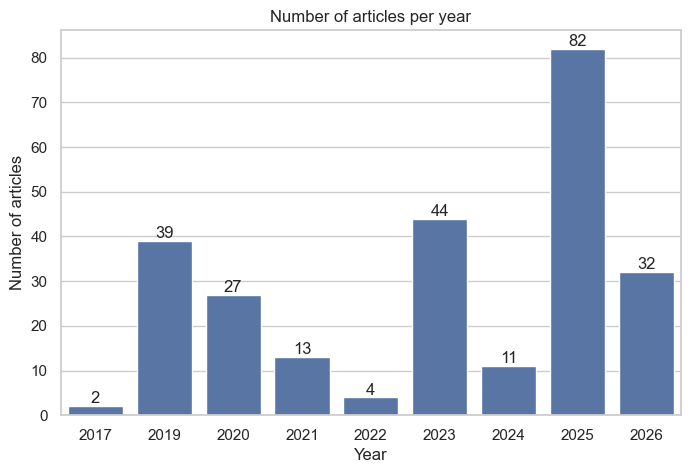

Date range: 2017-05-17 -> 2026-07-09


In [305]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="year", color="#4C72B0")
ax.bar_label(ax.containers[0])          # writes the number on top of each bar

plt.title("Number of articles per year")
plt.xlabel("Year")
plt.ylabel("Number of articles")
plt.show()

print("Date range:", df["date"].min().date(), "->", df["date"].max().date())

##### Top News Sources

finding out which publisher covers PSN the most

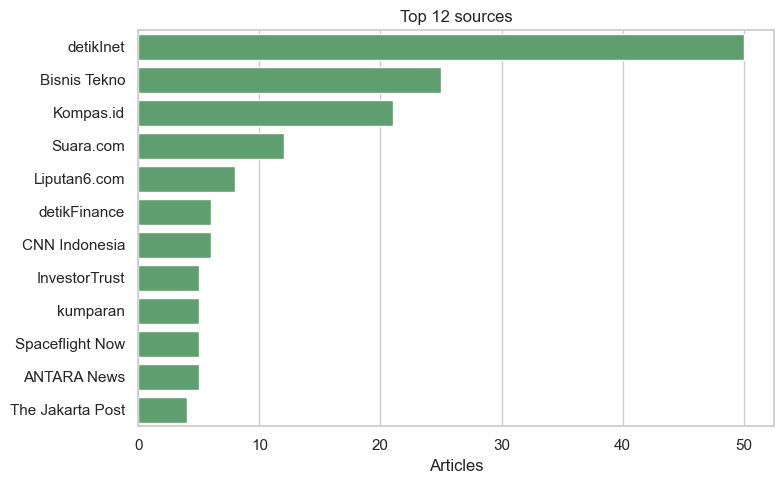

In [306]:
top_sources = df["source"].value_counts().head(12)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=top_sources.values, y=top_sources.index, ax=ax, color="#55A868")
ax.set_title("Top 12 sources")
ax.set_xlabel("Articles")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

##### Article length and language

Showing the distribution of article length and the split of indonesian and english text.

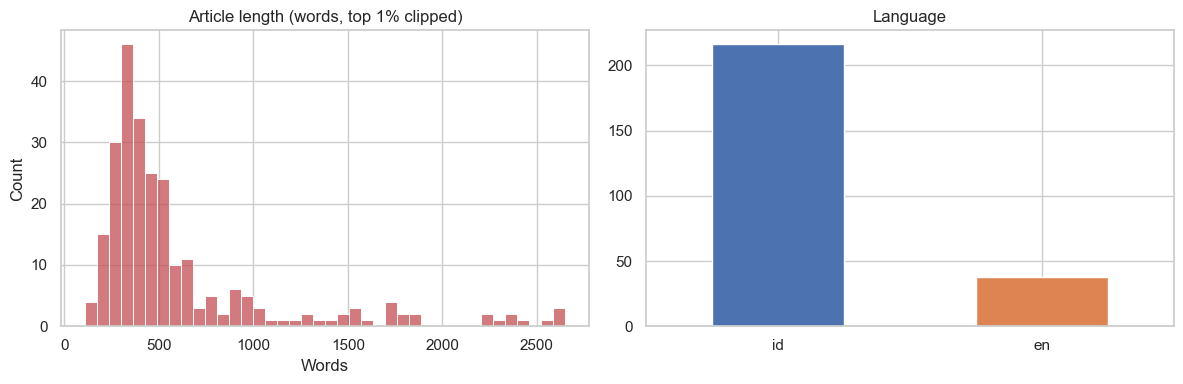

count     254.0
mean      612.0
std       529.0
min       108.0
25%       319.0
50%       417.0
75%       627.0
max      3093.0
Name: n_words, dtype: float64

In [307]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["n_words"].clip(upper=df["n_words"].quantile(0.99)), bins=40, ax=axes[0], color="#C44E52")
axes[0].set_title("Article length (words, top 1% clipped)")
axes[0].set_xlabel("Words")

df["lang"].value_counts().plot(kind="bar", ax=axes[1], color=["#4C72B0", "#DD8452"])
axes[1].set_title("Language")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

df["n_words"].describe().round(0)

#### 5. Text preprocessing

For Text preprocessing, removing noise only would be the approach. it is not necessary to remove stopwords, because the language model needs real sentence structure to produce good vectors. Stopwords are removed later, only when extracting the topic keyword (inside the CountVectorizer).

##### Stopword list for the topic keywords

In [308]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

sastrawi_stopwords = set(StopWordRemoverFactory().get_stop_words())

indonesian_extra_stopwords = set('''
ujar katanya mengatakan menurut tersebut sebesar sekitar secara sangat selain seperti sehingga bahwa lalu
kemudian pun lagi sampai melalui terhadap tentang baru tahun bulan hari senin selasa rabu kamis jumat sabtu
minggu jakarta wib kata sebut disebut banyak semua setiap beberapa nya dua tiga satu juga kini saat bisa
dapat para hingga serta agar namun tetapi dalam menjadi lebih memiliki milik
'''.split())

english_stopwords = set('''
the and of to in for with that is are was were be been by on at as from it its this these those an a or
has have had will would can could their they we our you he she his her not but also more than which who
said says about into over after before between up out new one two
'''.split())

domain_stopwords = set('''
satelit satellite satellites nusantara indonesia indonesian psn pt pasifik tbk persero
'''.split())



stopwords = sorted(sastrawi_stopwords | indonesian_extra_stopwords | english_stopwords | domain_stopwords)
print(f"{len(stopwords)} stopwords in total (Sastrawi alone: {len(sastrawi_stopwords)})")

234 stopwords in total (Sastrawi alone: 123)


#### 6. Topic Modelling with BERTopic

BERTopic builds topics in four stages:

1. **Embedding** - Turning each article into a Vector to capture its context by multilingual sentence-transformer
2. **Dimensionality Reduction** - UMAP compresses the vectors into fewer dimensions so clustering works well in lower dimensions.
3. **Clustering** - HDBSCAN groups nearby vectors into topics and marks leftovers as outliers.
4. **Describe** - c-TF-IDF finds the words that make each cluster distinctiv, which it'll find the words that best characterize each cluster. then it will become the topic keywords.



##### Prepare Documents

since the embedding model only reads the first 128 tokens, building each document as title + the beginning of the article body will be implemented, which carries the main point of the article

In [309]:
df["doc"] = df["title_clean"] + ". " + df["text"].str.slice(0, 1500)

docs = df["doc"].tolist()
print(f"{len(docs)} documents for topic modelling")
print("example:", docs[0][:300], "...")

254 documents for topic modelling
example: Satelit Nano Pertama Buatan Mahasiswa Indonesia Siap Meluncur. Rencananya, satelit ini akan mulai meluncur pada akhir 2017 Liputan6.com, Jakarta - Sekelompok mahasiswa Surya University telah mengawali pengembangan satelit nano. Satelit yang memiliki ukuran lebih kecil dari satelit standar ini diklai ...


##### Compute Embedded Model

Converts every document into a vector using multilingual model that understands both languages.

In [310]:
from sentence_transformers import SentenceTransformer

embed_model = SentenceTransformer(embedding_model)
embeddings = embed_model.encode(docs, show_progress_bar=True, batch_size=32)
print("Embedding shape:", embeddings.shape)

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Embedding shape: (254, 384)


In [311]:
print(len(df), len(docs), embeddings.shape)

254 254 (254, 384)


##### Configure the main pipeline

a function will be implemented to apply the same configuration. Key settings:
- ```min_cluster_size``` (HDBSCAN) : The smallest group of articles that can become a topic. since the dataset is small, a value around 8 to 10 gives a manageable number of topics
- ```n_neighbors``` (UMAP) : lower focuses on local structure
- ```CountVectorizer``` : removes stopfowrds from the keywords and allows two-word phareses. with additional configuration. ```min_df=2``` ignores words that appear in just one article, ```token_pattern`` keeps letters only.
- ```random_state``` keeps results reproducible

In [312]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

umap_model = UMAP(n_neighbors=10, n_components=5, min_dist=0.0, metric="cosine", random_state=random_state)

hdbscan_model = HDBSCAN(min_cluster_size=8, min_samples=3, metric="euclidean",
                        cluster_selection_method="eom", prediction_data=True)

vectorizer_model = CountVectorizer(stop_words=stopwords, ngram_range=(1,2), min_df=2,
                                   token_pattern=r"(?u)\b[^\W\d_]{2,}\b")

topic_model = BERTopic(
    embedding_model=embed_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    top_n_words=10,
    calculate_probabilities=False,
    verbose=True,
)

topics, _ = topic_model.fit_transform(docs, embeddings)
print("Topics found (excluding outliers):", len(set(topics)) - (1 if -1 in topics else 0))
print("Outlier articles (-1):", sum(t == -1 for t in topics))

2026-11-05 13:36:43,017 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-05 13:36:43,282 - BERTopic - Dimensionality - Completed ✓
2026-11-05 13:36:43,283 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-05 13:36:43,291 - BERTopic - Cluster - Completed ✓
2026-11-05 13:36:43,294 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-05 13:36:43,379 - BERTopic - Representation - Completed ✓


Topics found (excluding outliers): 10
Outlier articles (-1): 49


##### Topics EDA After Model

using ```get_topic_info()``` function, lists every topic with its size and top words. -1 means its on the outlier group.

In [313]:
topic_info = topic_model.get_topic_info()
topic_info[["Topic", "Count", "Name", "Representation"]]

,Topic,Count,Name,Representation
0,-1,49,-1_orbit_satria_adi_peluncuran,"[orbit, satria, adi, peluncuran, slot, palapa, lima, utama, internet, slot orbit]"
1,0,58,0_spacex_lima_snl_peluncuran,"[spacex, lima, snl, peluncuran, falcon, roket, canaveral, launch, cape canaveral, cape]"
2,1,37,1_satria_internet_proyek_thales,"[satria, internet, proyek, thales, bakti, orbit, bumi, kominfo, titik, stasiun]"
3,2,20,2_kapasitas_satria_starlink_waktu,"[kapasitas, satria, starlink, waktu, florida, internet, diluncurkan, lima, orbit, kebutuhan]"
4,3,15,3_kapasitas_februari_teknologi_diluncurkan,"[kapasitas, februari, teknologi, diluncurkan, hts, band, menggunakan, broadband, gbps, high]"
5,4,15,4_palapa_gagal_xichang_china,"[palapa, gagal, xichang, china, orbit, march, long march, long, roket, indosat]"
6,5,14,5_perusahaan_teknologi_adi_kolaborasi,"[perusahaan, teknologi, adi, kolaborasi, adiwoso, adi rahman, rahman, berbasis, antariksa, industri]"
7,6,12,6_lima_antariksa_digital_industri,"[lima, antariksa, digital, industri, teknologi, rudiantara, internet, negara, konektivitas, nasional]"
8,7,12,7_proyek_strategis_nasional_adi,"[proyek, strategis, nasional, adi, pembangunan, bidang, proyek strategis, strategis nasional, teknologi, pemerintah]"
9,8,12,8_lima_connectivity_capacity_launch,"[lima, connectivity, capacity, launch, snl, internet, space, internet access, access, philippines]"


##### Reducing Outliers

```-1``` are the outliers, which in this case that there are a lot of outliers. so we need to explore further about the outliers from clustering.

In [314]:
outliers = df[[t == -1 for t in topics]]
outliers_no_title = outliers[~outliers["psn_in_title"]]

print("Outliers:", len(outliers), "| PSN not in title:", len(outliers_no_title))
outliers_no_title[["title_clean", "source", "psn_sentences"]].sort_values("psn_sentences")

Outliers: 49 | PSN not in title: 16


,title_clean,source,psn_sentences
38,Kratos Wins $5.7 Million Contract for PNS Ground Station Support,Via Satellite,3
40,Indonesia Sukses Dapatkan Tiga Slot Orbit Satelit,www.batamtimes.co,3
68,Telkom Pakai Slot Orbit Satelit 113 BT yang Sebelumnya Diisi Indosat,Kumparan.com,3
80,"Adi Rahman, Penemu & Pengusaha yang Bakal Luncurkan Satelit Terbesar se-Asia",kumparan,3
69,"Puing Ditemukan di Kalteng, Begini Cerita Roket China Meledak 10 April Silam",detikNews,4
84,Thales Indonesia: Delivering digital solutions 40 years and beyond,The Jakarta Post,4
85,"Proyek Satelit SATRIA Masuk Tahap Finalisasi, Begini Perkembangannya",detikFinance,4
230,"Satelit N5 Resmi Kantongi Izin Operasi Komdigi, Bawa Kapasitas Internet 160 Gbps",detikInet,4
59,Kominfo berhasil pertahankan slot orbit satelit Indonesia di ITU,ANTARA News Sulteng,5
101,"Laporan dari Florida: Satelit Satria-1 Telan Biaya Rp 8 Triliun, Bakal Layani Internet Wilayah 3T Secara Gratis",Liputan6.com,5


from the 49 outliers it shows that there are a lot of news or article that is indeed talking about psn. we can mitigate that by using ```reduce_outliers``` function from BERTopic to reduce its impact.

In [315]:
topics_before = list(topics)
print("Outliers before:", sum(t == -1 for t in topics_before))

Outliers before: 49


In [316]:
for t in [0.5, 0.6, 0.7, 0.75, 0.8]:
    test = topic_model.reduce_outliers(docs, topics_before, strategy="embeddings",
                                       embeddings=embeddings, threshold=t)
    print(t, "->", sum(x == -1 for x in test), "outliers left")

0.5 -> 0 outliers left
0.6 -> 0 outliers left
0.7 -> 6 outliers left
0.75 -> 13 outliers left
0.8 -> 24 outliers left


from the selection of theresholds from BERTopic we can see how many outliers are left based on the values. i decided to go with 6 because reducing all of the outliers because we still want articles that are not about psn to be in the outliers

In [317]:
new_topics = topic_model.reduce_outliers(
    docs, topics_before,
    strategy="embeddings",
    embeddings=embeddings,
    threshold=0.7,
)
print("Outliers after:", sum(t == -1 for t in new_topics))

Outliers after: 6


In [318]:
topic_model.update_topics(docs, topics=new_topics, vectorizer_model=vectorizer_model)
topics = new_topics
topic_model.get_topic_info()[["Topic", "Count", "Name", "Representation"]]

2026-11-05 13:36:43,685 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


,Topic,Count,Name,Representation
0,-1,6,-1_satria_kota_uji_penyiaran,"[satria, kota, uji, penyiaran, uji coba, coba, pelaksanaan, adi, various, bumn]"
1,0,59,0_spacex_lima_peluncuran_snl,"[spacex, lima, peluncuran, snl, falcon, roket, canaveral, cape canaveral, cape, launch]"
2,1,38,1_satria_internet_proyek_bakti,"[satria, internet, proyek, bakti, thales, kominfo, orbit, bumi, thales alenia, alenia]"
3,2,29,2_orbit_slot orbit_slot_kapasitas,"[orbit, slot orbit, slot, kapasitas, waktu, bt, diluncurkan, starlink, operator, satria]"
4,3,26,3_kapasitas_peluncuran_serikat_amerika serikat,"[kapasitas, peluncuran, serikat, amerika serikat, amerika, adi, florida, gbps, satria, teknologi]"
5,4,18,4_palapa_gagal_china_orbit,"[palapa, gagal, china, orbit, roket, indosat, march, long march, long, psns]"
6,5,20,5_perusahaan_adi_teknologi_adiwoso,"[perusahaan, adi, teknologi, adiwoso, adi rahman, rahman, berbasis, direktur, nasional, rahman adiwoso]"
7,6,13,6_lima_teknologi_digital_antariksa,"[lima, teknologi, digital, antariksa, industri, konektivitas, rudiantara, internet, nasional, memperkuat]"
8,7,12,7_proyek_strategis_nasional_adi,"[proyek, strategis, nasional, adi, pembangunan, bidang, proyek strategis, strategis nasional, teknologi, pemerintah]"
9,8,21,8_lima_capacity_orbit_snl,"[lima, capacity, orbit, snl, internet, adi, filipina, connectivity, launch, access]"


```update_topics``` rebuilds the topic keywords using the new assignments, and ```topics``` holds the fixed version. therefore each article topics before and after will be saved, so they can be compared

In [319]:
df["topic_before"] = topics_before
df["topic_after"] = topics

In [320]:
moved = df[(df["topic_before"] == -1) & (df["topic_after"] != -1)]
still_outliers = df[df["topic_after"] == -1]

print("Moved into topics:", len(moved))
print("Still outliers:", len(still_outliers))

moved[["title_clean", "psn_in_title", "psn_sentences", "topic_after"]].sort_values("topic_after")

Moved into topics: 43
Still outliers: 6


,title_clean,psn_in_title,psn_sentences,topic_after
91,"Satelit Satria Meluncur 19 Juni, PSN: Infrastruktur Bumi Sudah Siap",True,5,0
101,"Laporan dari Florida: Satelit Satria-1 Telan Biaya Rp 8 Triliun, Bakal Layani Internet Wilayah 3T Secara Gratis",False,5,1
252,"PSN dan Telkomsat Ajukan Slot Orbit Satelit LEO ke ITU, Ingin Saingi Starlink",True,3,2
80,"Adi Rahman, Penemu & Pengusaha yang Bakal Luncurkan Satelit Terbesar se-Asia",False,3,2
70,Telkom Gantikan Indosat untuk Luncurkan Satelit Multifungsi Indonesia,False,6,2
68,Telkom Pakai Slot Orbit Satelit 113 BT yang Sebelumnya Diisi Indosat,False,3,2
59,Kominfo berhasil pertahankan slot orbit satelit Indonesia di ITU,False,5,2
40,Indonesia Sukses Dapatkan Tiga Slot Orbit Satelit,False,3,2
6,Satelit Palapa Nusantara Dua Indosat Ooredoo Ditargetkan akan Luncur Mei 2020,True,4,2
253,"Komdigi: RI Siapkan Satelit LEO Nasional, Telkomsat dan PSN Ajukan Slot Orbit",True,1,2


In [321]:
still_outliers[["title_clean", "source", "psn_in_title", "psn_sentences"]]

,title_clean,source,psn_in_title,psn_sentences
38,Kratos Wins $5.7 Million Contract for PNS Ground Station Support,Via Satellite,False,3
41,Satelit Nusantara Dua Segera Gantikan Palapa-D Milik Indosat,republika.co.id,True,12
56,"Satelit Nusantara Dua Gagal Orbit, Penyiaran Bakal Numpang Satelit Telkom dan BRI?",Uzone.id,True,10
84,Thales Indonesia: Delivering digital solutions 40 years and beyond,The Jakarta Post,False,4
108,"Kisah Inspiratif Nia, Wanita 29 Tahun Asal Indonesia Pembuat Satria-1 Satelit Terbesar di Asia",Liputan6.com,False,7
128,"Sukses, Uji Coba Satria-1 Dihadiri Menkominfo Budi Arie Setiadi",Suara Merdeka Jakarta,False,5


Using a threshold of 0.7 for `reduce_outliers` moved 43 of the 49 outliers into the existing topics, and 6 stayed as outliers. A lower threshold moved every article, including weak matches, which can make the topics less clean. Looking at the 6 remaining articles, most of them are still about PSN, but they mix several themes and were not similar enough to any single topic, so they are kept as outliers instead of being forced into a topic.

then saving the final topic will be done on every article, so the sentiment results can be grouped by topic later. 

In [322]:
df["topic"] = topics
names = topic_model.get_topic_info().set_index("Topic")["Name"]
df["topic_name"] = df["topic"].map(names).fillna("outlier")

df[["doc_id", "title_clean", "topic", "topic_name"]].head(10)

,doc_id,title_clean,topic,topic_name
0,0,Satelit Nano Pertama Buatan Mahasiswa Indonesia Siap Meluncur,2,2_orbit_slot orbit_slot_kapasitas
1,1,PSN Bikin Satelit Baru untuk Sebar Internet di Indonesia,3,3_kapasitas_peluncuran_serikat_amerika serikat
2,2,Satelit Kapasitas Jumbo Nusantara Satu Mengorbit pada Februari,3,3_kapasitas_peluncuran_serikat_amerika serikat
3,3,PSN Siap Luncurkan Satelit dengan Kapasitas Broadband Terbesar di Indonesia,3,3_kapasitas_peluncuran_serikat_amerika serikat
4,4,"Satelit Nusantara Satu PSN Meluncur Februari 2019, Dibawa oleh SpaceX",3,3_kapasitas_peluncuran_serikat_amerika serikat
5,5,Satelit Nusantara Satu buatan Indonesia segera meluncur,3,3_kapasitas_peluncuran_serikat_amerika serikat
6,6,Satelit Palapa Nusantara Dua Indosat Ooredoo Ditargetkan akan Luncur Mei 2020,2,2_orbit_slot orbit_slot_kapasitas
7,7,Falcon 9 launch set for Thursday at Cape Canaveral,0,0_spacex_lima_peluncuran_snl
8,8,"Siap-Siap, Satelit Nusantara Satu ""Mengangkasa"" Besok",3,3_kapasitas_peluncuran_serikat_amerika serikat
9,9,"Meluncur Esok Hari, Ini Fakta Satelit Nusantara Satu",3,3_kapasitas_peluncuran_serikat_amerika serikat


In [323]:
df[df["topic"] == 7][["title_clean", "psn_in_title", "psn_sentences"]]

,title_clean,psn_in_title,psn_sentences
30,"Perjalanan ""Infrastruktur Langit"": Mega Proyek Sejak Orde Baru",False,4
77,"Adi Rahman Adiwoso, Tinggalkan AS Nekat Bangun Satelit di RI",False,6
106,"Nia Asmady, Sosok Muda Berbakat di Balik Peluncuran Satelit RI Terbesar di Asia",False,7
201,"Adi Rahman Adiwoso, Bapak Satelit Indonesia yang Melawan Arus",False,8
204,Mimpi Besar CEO PSN: Indonesia Jadi Pusat Antariksa Dunia,True,2
214,Proyek Strategis Nasional Prabowo Sektor Teknologi: Satelit Sampai Palapa Ring,False,5
215,"Prabowo Tetapkan 5 Proyek Strategis Teknologi, Ini Daftarnya",False,4
216,Satelit Multifungsi dan Palapa Ring Integrasi Masuk Daftar Proyek Strategis Nasional,False,13
217,Adi Rahman Adiwoso Raih Penghargaan Aerospace Technology Pioneer di BIG 40 Award,False,5
219,"Masuk PSN, Komdigi Ungkap Penggunaan Teknologi Satelit SATRIA-2",True,1


##### Topic Visualization

here i will visualize the topcs by the top keywords per topic and their score (c-TF-IDF) weight and how many articles falls into each topic

In [324]:
topic_model.visualize_barchart(top_n_topics=12, n_words=8, height=300)

below are the topic distribution on each articles

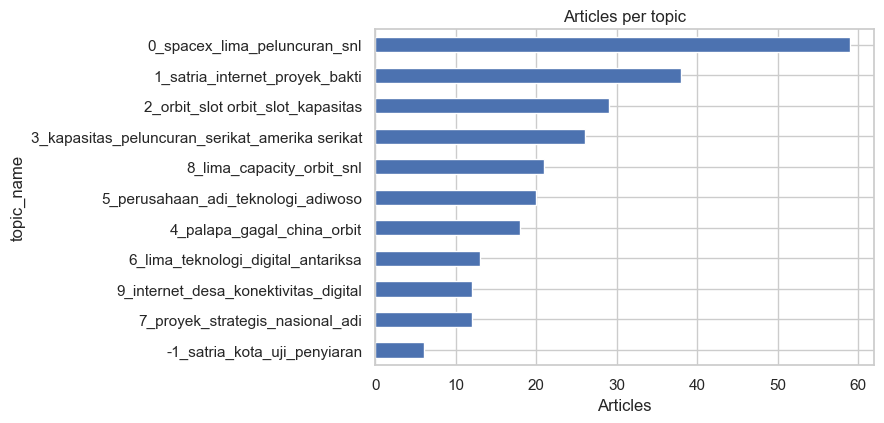

In [326]:
sizes = df["topic_name"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, max(3, 0.4 * len(sizes))))
sizes.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Articles per topic")
ax.set_xlabel("Articles")
plt.tight_layout()
plt.show()

below are the Topics overtime over the years

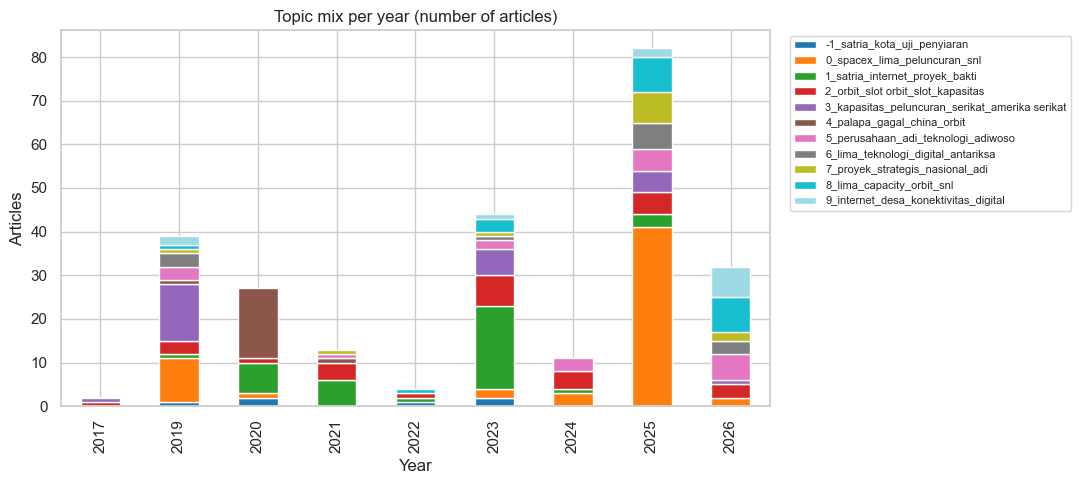

In [329]:
topic_year = pd.crosstab(df["year"], df["topic_name"])

topic_year.plot(kind="bar", stacked=True, figsize=(11, 5), colormap="tab20")
plt.title("Topic mix per year (number of articles)")
plt.xlabel("Year")
plt.ylabel("Articles")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

#### 7. Sentiment Analysis